# Self-RAG: Learning to Retrieve, Generate, and Critique through Self-Reflection

**Paper:** [arXiv:2310.11511](https://arxiv.org/abs/2310.11511)
**Authors:** Akari Asai, Zeqiu Wu, Yizhong Wang, Avirup Sil, Hannaneh Hajishirzi (2023; ICLR 2024)

This notebook implements a simplified Self-RAG from scratch in PyTorch, on a synthetic QA task.
Self-RAG trains a language model to decide when to retrieve, whether retrieved passages are relevant,
and whether its own answer is supported by them — using special reflection tokens.

**Simplifications vs the paper** (same list as README and CODE_ARCHITECTURE):
- Synthetic QA task (40 subjects, two types, dynamic passages) instead of 150k instruction-output pairs
- 2-layer Transformer (449K params) instead of Llama 2 7B/13B
- 40 epochs with AdamW (lr 1e-3) instead of fine-tuning Llama 2
- Dynamic passage provider instead of Contriever-MS MARCO
- Ground-truth reflection labels instead of GPT-4-annotated critic model

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import random
import time
import math

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters ---
VOCAB_SIZE = 200
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 2
FFN_DIM = 512
EPOCHS = 40
BATCH_SIZE = 128
LR = 1e-3
MAX_DOCS = 3
MAX_SEQ_LEN = 48

# Special tokens
PAD_TOK = 0
BOS_TOK = 1
EOS_TOK = 2
QUERY_TOK = 3
SEP_TOK = 4
RETRIEVE_TOK = 5
RELEVANT_TOK = 6
SUPPORTED_TOK = 7

# 40 subjects: tokens 10-49
N_SUBJECTS = 40
SUBJECT_START = 10
# First 20 (10-29): factual. Last 20 (30-49): open-ended.
N_FACTUAL = 20

# Answer tokens: 50-59 (10 possible answers)
ANSWER_START = 50
N_ANSWERS = 10

# Filler tokens: 60-99
FILLER_START = 60
N_FILLER = 40

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


## 2. Synthetic Data — Dynamic Knowledge Base and QA Pairs

40 subjects, each in a 4-token question `[BOS, subject, token2, QUERY]`. All answers are in range 50–59.

- **Factual subjects (0–19):** `token2` is a random filler (60–99). The answer is a random token (50–59)
  generated fresh per instance and stored ONLY in a dynamically generated passage. The model cannot
  know the answer without retrieval. Retrieve=yes.
- **Open-ended subjects (20–39):** `token2` IS the answer (50–59). The answer is directly in the question.
  The dynamically generated passage contains a **distractor**: a different answer token (50–59).
  Since all answers share the same 10-token range, the distractor looks plausible but is wrong.
  Retrieve=no.

The question format is identical for both types (4 tokens, same structure). The model must **learn**
which subjects are factual (need retrieval) vs open-ended (answer is in the question, retrieval introduces
a distractor). This mirrors Self-RAG's key insight: indiscriminate retrieval can hurt on questions that
do not require external knowledge.

In [2]:
def generate_qa_pair():
    """Generate one QA pair with dynamic passage and ground-truth reflection labels."""
    subj_idx = random.randint(0, N_SUBJECTS - 1)
    subject = SUBJECT_START + subj_idx
    
    if subj_idx < N_FACTUAL:
        # Factual: token2 is filler, answer is random (only in passage)
        token2 = FILLER_START + random.randint(0, N_FILLER - 1)
        answer = ANSWER_START + random.randint(0, N_ANSWERS - 1)
        question = [BOS_TOK, subject, token2, QUERY_TOK]
        # Passage with correct answer
        passage = [subject, answer,
                   FILLER_START + random.randint(0, N_FILLER-1),
                   FILLER_START + random.randint(0, N_FILLER-1),
                   FILLER_START + random.randint(0, N_FILLER-1)]
        # Distractor passage with wrong answer
        wrong = ANSWER_START + random.randint(0, N_ANSWERS - 1)
        while wrong == answer:
            wrong = ANSWER_START + random.randint(0, N_ANSWERS - 1)
        distractor_passage = [subject, wrong] + [FILLER_START + random.randint(0, N_FILLER-1) for _ in range(3)]
        retrieve = 1; isrel = 1; issup = 0; isuse = 1
    else:
        # Open-ended: token2 IS the answer, passage has distractor
        answer = ANSWER_START + (subj_idx - N_FACTUAL) % N_ANSWERS
        question = [BOS_TOK, subject, answer, QUERY_TOK]
        # Distractor passage (wrong answer)
        wrong = ANSWER_START + random.randint(0, N_ANSWERS - 1)
        while wrong == answer:
            wrong = ANSWER_START + random.randint(0, N_ANSWERS - 1)
        passage = [subject, wrong] + [FILLER_START + random.randint(0, N_FILLER-1) for _ in range(3)]
        distractor_passage = [subject, wrong] + [FILLER_START + random.randint(0, N_FILLER-1) for _ in range(3)]
        retrieve = 0; isrel = 0; issup = 2; isuse = 1
    
    return {
        'question': question, 'answer': answer,
        'subj_idx': subj_idx, 'is_factual': subj_idx < N_FACTUAL,
        'passage': passage, 'distractor_passage': distractor_passage,
        'retrieve': retrieve, 'isrel': isrel, 'issup': issup, 'isuse': isuse,
    }

def generate_dataset(n):
    return [generate_qa_pair() for _ in range(n)]

train_data = generate_dataset(12000)
val_data = generate_dataset(1000)
n_fact = sum(1 for d in train_data if d['is_factual'])
print(f'Subjects: {N_FACTUAL} factual, {N_SUBJECTS - N_FACTUAL} open-ended')
print(f'Answer range: {ANSWER_START}-{ANSWER_START + N_ANSWERS - 1} ({N_ANSWERS} possible)')
print(f'Training: {len(train_data)} ({n_fact} factual, {len(train_data)-n_fact} open-ended)')
print(f'Validation: {len(val_data)}')

for i in range(4):
    ex = train_data[i]
    qt = 'factual' if ex['is_factual'] else 'open'
    print(f'  Example {i} ({qt}): Q={ex["question"]}, A={ex["answer"]}, '
          f'passage={ex["passage"]}, ret={ex["retrieve"]}')

Subjects: 20 factual, 20 open-ended
Answer range: 50-59 (10 possible)
Training: 12000 (5998 factual, 6002 open-ended)
Validation: 1000
  Example 0 (factual): Q=[1, 17, 61, 3], A=54, passage=[17, 54, 75, 74, 68], ret=1
  Example 1 (open): Q=[1, 37, 57, 3], A=57, passage=[37, 50, 61, 65, 73], ret=0
  Example 2 (factual): Q=[1, 11, 95, 3], A=53, passage=[11, 53, 94, 86, 74], ret=1
  Example 3 (factual): Q=[1, 20, 87, 3], A=55, passage=[20, 55, 77, 69, 73], ret=1


## 3. Retriever — Passage Provider

Returns top-3 passages per question. For factual questions, one passage has the correct answer.
For open-ended questions, all passages contain distractors (wrong answers in the same 50–59 range).

In [3]:
def get_retrieved_passages(ex):
    """Return 3 passages for a question."""
    passages = [ex['passage'], ex['distractor_passage']]
    # Third passage: random subject with random answer
    rand_subj = SUBJECT_START + random.randint(0, N_SUBJECTS - 1)
    rand_ans = ANSWER_START + random.randint(0, N_ANSWERS - 1)
    passages.append([rand_subj, rand_ans] + [FILLER_START + random.randint(0, N_FILLER-1) for _ in range(3)])
    return passages

# Test
ex = train_data[0]
ps = get_retrieved_passages(ex)
qt = 'factual' if ex['is_factual'] else 'open'
print(f'Test ({qt}): answer={ex["answer"]}')
for i, p in enumerate(ps):
    has_answer = ex['answer'] in p
    print(f'  Passage {i}: {p} (contains answer: {has_answer})')

Test (factual): answer=54
  Passage 0: [17, 54, 75, 74, 68] (contains answer: True)
  Passage 1: [17, 51, 94, 65, 97] (contains answer: False)
  Passage 2: [49, 50, 85, 97, 69] (contains answer: False)


## 4. Model — TinySelfRAG

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=MAX_SEQ_LEN):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TinySelfRAG(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, D_MODEL, padding_idx=PAD_TOK)
        self.pos_enc = PositionalEncoding(D_MODEL)
        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL, nhead=N_HEADS, dim_feedforward=FFN_DIM,
            dropout=0.1, activation='gelu', batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=N_LAYERS)
        self.retrieve_head = nn.Linear(D_MODEL, 2)
        self.isrel_head = nn.Linear(D_MODEL, 2)
        self.issup_head = nn.Linear(D_MODEL, 3)
        self.isuse_head = nn.Linear(D_MODEL, 2)
        self.answer_head = nn.Linear(D_MODEL, VOCAB_SIZE)
    
    def forward(self, input_ids):
        emb = self.pos_enc(self.embedding(input_ids))
        sl = input_ids.size(1)
        cmask = torch.triu(torch.ones(sl, sl), diagonal=1).bool().to(input_ids.device)
        pmask = (input_ids == PAD_TOK)
        h = self.transformer(emb, mask=cmask, src_key_padding_mask=pmask)
        # Position 1 (subject) for Retrieve
        ret_logits = self.retrieve_head(h[:, 1])
        # Last non-pad position for other heads
        lengths = (~pmask).sum(dim=1)
        last_idx = (lengths - 1).clamp(min=0)
        lh = h[torch.arange(input_ids.size(0)), last_idx]
        return {
            'retrieve': ret_logits,
            'isrel': self.isrel_head(lh),
            'issup': self.issup_head(lh),
            'isuse': self.isuse_head(lh),
            'answer': self.answer_head(lh),
        }

model = TinySelfRAG().to(DEVICE)
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Total parameters: 449,105


/var/folders/29/sr_hdh215zd4q_shw6vgbhqw0000gn/T/ipykernel_19503/2894696138.py:21: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=N_LAYERS)


## 5. Loss Function and Data Preparation

Multi-task loss: answer cross-entropy + 0.5 * each reflection-token cross-entropy.

Training only uses passages (always-retrieve mode). The model must learn:
- For factual subjects: read the answer from the passage (since token2 is filler)
- For open-ended subjects: ignore the passage (distractor) and read the answer from token2 in the question

This creates a natural tension: the model learns to use passages for some subjects and ignore them for others,
which is exactly the Retrieve token's job.

In [5]:
def build_input_sequence(question, passages, include_passages=True):
    seq = list(question) + [SEP_TOK]
    if include_passages and passages is not None:
        for p in passages:
            seq.extend(p)
            seq.append(SEP_TOK)
        seq += [RETRIEVE_TOK, RELEVANT_TOK, SUPPORTED_TOK]
    else:
        seq.append(RETRIEVE_TOK)
    return seq

def prepare_batch(data, include_passages=True):
    inputs, answers, rets, rels, sups, uses = [], [], [], [], [], []
    for ex in data:
        if include_passages:
            passages = get_retrieved_passages(ex)
            seq = build_input_sequence(ex['question'], passages, include_passages=True)
        else:
            seq = build_input_sequence(ex['question'], None, include_passages=False)
        inputs.append(seq)
        answers.append(ex['answer'])
        rets.append(ex['retrieve'])
        rels.append(ex['isrel'])
        sups.append(ex['issup'])
        uses.append(ex['isuse'])
    ml = min(max(len(s) for s in inputs), MAX_SEQ_LEN)
    padded = [s[:ml] + [PAD_TOK] * max(0, ml - len(s[:ml])) for s in inputs]
    return (torch.tensor(padded).to(DEVICE), torch.tensor(answers).to(DEVICE),
            torch.tensor(rets).to(DEVICE), torch.tensor(rels).to(DEVICE),
            torch.tensor(sups).to(DEVICE), torch.tensor(uses).to(DEVICE))

def compute_loss(o, a, r, rel, sup, use):
    la = F.cross_entropy(o['answer'], a)
    lr = F.cross_entropy(o['retrieve'], r)
    lrel = F.cross_entropy(o['isrel'], rel)
    lsup = F.cross_entropy(o['issup'], sup)
    lu = F.cross_entropy(o['isuse'], use)
    return la + 0.5 * (lr + lrel + lsup + lu)

## 6. Training Loop

In [6]:
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

def make_batches(data, bs, shuffle=True):
    idx = list(range(len(data)))
    if shuffle:
        random.shuffle(idx)
    for i in range(0, len(idx), bs):
        yield [data[j] for j in idx[i:i+bs]]

# Train ONLY with passages — model learns to use passages for factual, ignore for open-ended
history = {'loss': [], 'ans_w': [], 'ans_wo': [], 'ret': [], 'rel': [], 'sup': [], 'use': []}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    ep_loss, n_b = 0.0, 0
    for batch in make_batches(train_data, BATCH_SIZE):
        inp, ans, ret, rel, sup, use = prepare_batch(batch, include_passages=True)
        optimizer.zero_grad()
        out = model(inp)
        loss = compute_loss(out, ans, ret, rel, sup, use)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        ep_loss += loss.item()
        n_b += 1
    
    avg = ep_loss / n_b
    history['loss'].append(avg)
    
    model.eval()
    with torch.no_grad():
        # With passages
        vi, va, vr, vrel, vsup, vu = prepare_batch(val_data, include_passages=True)
        vo = model(vi)
        ans_w = (vo['answer'].argmax(1) == va).float().mean().item()
        ra = (vo['retrieve'].argmax(1) == vr).float().mean().item()
        ela = (vo['isrel'].argmax(1) == vrel).float().mean().item()
        sa = (vo['issup'].argmax(1) == vsup).float().mean().item()
        ua = (vo['isuse'].argmax(1) == vu).float().mean().item()
        # Without passages
        vi2, va2, _, _, _, _ = prepare_batch(val_data, include_passages=False)
        vo2 = model(vi2)
        ans_wo = (vo2['answer'].argmax(1) == va2).float().mean().item()
        
        history['ans_w'].append(ans_w)
        history['ans_wo'].append(ans_wo)
        history['ret'].append(ra)
        history['rel'].append(ela)
        history['sup'].append(sa)
        history['use'].append(ua)
    
    if epoch == 1 or epoch % 5 == 0:
        print(f'Ep [{epoch:3d}/{EPOCHS}] loss {avg:.4f} ans_w {ans_w:.4f} ans_wo {ans_wo:.4f} '
              f'ret {ra:.4f} rel {ela:.4f} sup {sa:.4f} [{time.time()-start:.0f}s]')

print(f'\nTraining time: {time.time()-start:.0f}s')
print(f'Final answer acc (w/ passages): {history["ans_w"][-1]:.4f}')
print(f'Final answer acc (w/o passages): {history["ans_wo"][-1]:.4f}')
print(f'Final retrieve accuracy: {history["ret"][-1]:.4f}')

Ep [  1/40] loss 1.0130 ans_w 1.0000 ans_wo 0.5520 ret 1.0000 rel 1.0000 sup 1.0000 [3s]


Ep [  5/40] loss 0.0017 ans_w 1.0000 ans_wo 0.5350 ret 1.0000 rel 1.0000 sup 1.0000 [15s]


Ep [ 10/40] loss 0.0000 ans_w 1.0000 ans_wo 0.5360 ret 1.0000 rel 1.0000 sup 1.0000 [31s]


Ep [ 15/40] loss 0.0106 ans_w 1.0000 ans_wo 0.5440 ret 1.0000 rel 1.0000 sup 1.0000 [46s]


Ep [ 20/40] loss 0.0001 ans_w 1.0000 ans_wo 0.5450 ret 1.0000 rel 1.0000 sup 1.0000 [61s]


Ep [ 25/40] loss 0.0030 ans_w 1.0000 ans_wo 0.5410 ret 1.0000 rel 1.0000 sup 1.0000 [76s]


Ep [ 30/40] loss 0.0000 ans_w 1.0000 ans_wo 0.5410 ret 1.0000 rel 1.0000 sup 1.0000 [91s]


Ep [ 35/40] loss 0.0000 ans_w 1.0000 ans_wo 0.5410 ret 1.0000 rel 1.0000 sup 1.0000 [107s]


Ep [ 40/40] loss 0.0000 ans_w 1.0000 ans_wo 0.5410 ret 1.0000 rel 1.0000 sup 1.0000 [122s]

Training time: 122s
Final answer acc (w/ passages): 1.0000
Final answer acc (w/o passages): 0.5410
Final retrieve accuracy: 1.0000


## 7. Training Curves

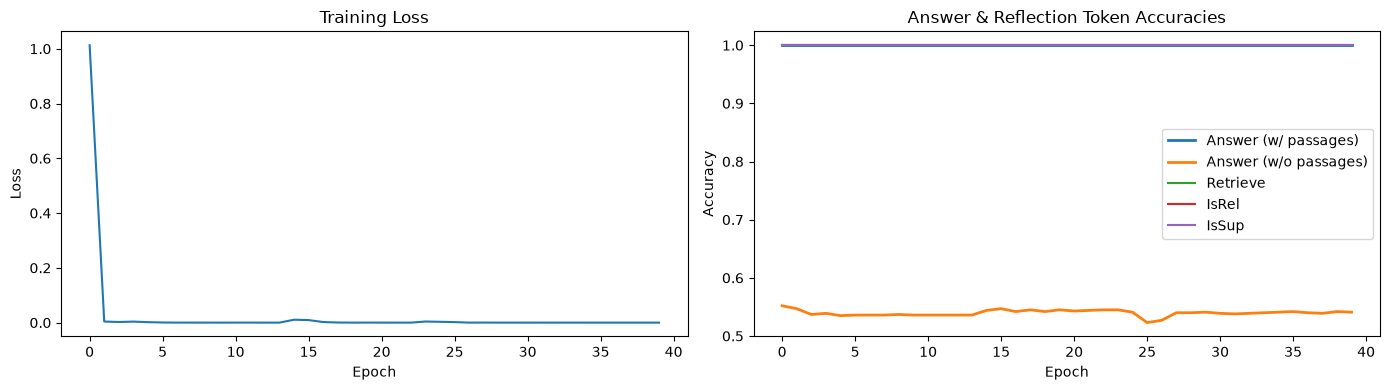

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['loss'])
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].set_title('Training Loss')
axes[1].plot(history['ans_w'], label='Answer (w/ passages)', linewidth=2)
axes[1].plot(history['ans_wo'], label='Answer (w/o passages)', linewidth=2)
axes[1].plot(history['ret'], label='Retrieve')
axes[1].plot(history['rel'], label='IsRel')
axes[1].plot(history['sup'], label='IsSup')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Answer & Reflection Token Accuracies'); axes[1].legend()
plt.tight_layout(); plt.show()

## 8. Evaluation — Adaptive vs Always-Retrieve vs Never-Retrieve

Three retrieval modes on the validation set:
1. **Always-retrieve:** always includes passages. On factual, correct answer is in a passage.
   On open-ended, all passages contain distractors (wrong answers in the same 50–59 range).
2. **Never-retrieve:** answer from question alone. Fails on factual (answer is random, not in question).
3. **Adaptive (Self-RAG):** model predicts Retrieve; only retrieves if yes.

In [8]:
def eval_single(model, question, passages, include_passages):
    seq = build_input_sequence(question, passages, include_passages)
    seq = seq[:MAX_SEQ_LEN] + [PAD_TOK] * max(0, MAX_SEQ_LEN - len(seq))
    t = torch.tensor([seq], dtype=torch.long).to(DEVICE)
    with torch.no_grad():
        return model(t)

def evaluate_modes(model, val_data):
    model.eval()
    res = {'always': [], 'never': [], 'adaptive': []}
    by_type = {'factual': {k: [] for k in res}, 'open': {k: [] for k in res}}
    retrieve_correct = []
    
    for ex in val_data:
        q, a = ex['question'], ex['answer']
        qt = 'factual' if ex['is_factual'] else 'open'
        passages = get_retrieved_passages(ex)
        
        out_ar = eval_single(model, q, passages, True)
        c_ar = (out_ar['answer'].argmax(1).item() == a)
        res['always'].append(c_ar); by_type[qt]['always'].append(c_ar)
        
        out_nr = eval_single(model, q, None, False)
        c_nr = (out_nr['answer'].argmax(1).item() == a)
        res['never'].append(c_nr); by_type[qt]['never'].append(c_nr)
        
        ret_dec = out_nr['retrieve'].argmax(1).item()
        retrieve_correct.append(ret_dec == ex['retrieve'])
        c_ad = c_ar if ret_dec == 1 else c_nr
        res['adaptive'].append(c_ad); by_type[qt]['adaptive'].append(c_ad)
    
    overall = {k: np.mean(v) for k, v in res.items()}
    typed = {qt: {m: np.mean(vs) for m, vs in ms.items()} for qt, ms in by_type.items()}
    ret_acc = np.mean(retrieve_correct)
    return overall, typed, ret_acc

overall, typed, ret_acc = evaluate_modes(model, val_data)
print('=== Retrieval Mode Comparison (Overall) ===')
for m in ['always', 'never', 'adaptive']:
    print(f'{m:12s}: {overall[m]:.4f}')
print(f'\nRetrieve token accuracy: {ret_acc:.4f}')
print('\n=== By Question Type ===')
for qt in ['factual', 'open']:
    print(f'  {qt}:')
    for m in ['always', 'never', 'adaptive']:
        print(f'    {m:12s}: {typed[qt][m]:.4f}')

=== Retrieval Mode Comparison (Overall) ===
always      : 1.0000
never       : 0.5410
adaptive    : 1.0000

Retrieve token accuracy: 1.0000

=== By Question Type ===
  factual:
    always      : 1.0000
    never       : 0.0838
    adaptive    : 1.0000
  open:
    always      : 1.0000
    never       : 1.0000
    adaptive    : 1.0000


## 9. Reflection Token Analysis

In [9]:
model.eval()
with torch.no_grad():
    vi, va, vr, vrel, vsup, vu = prepare_batch(val_data, include_passages=True)
    vo = model(vi)
    rp = vo['retrieve'].argmax(1)
    lp = vo['isrel'].argmax(1)
    sp = vo['issup'].argmax(1)
    up = vo['isuse'].argmax(1)
    print('=== Reflection Token Accuracies (with passages) ===')
    print(f'Retrieve: {(rp == vr).float().mean().item():.4f}')
    print(f'IsRel:    {(lp == vrel).float().mean().item():.4f}')
    print(f'IsSup:    {(sp == vsup).float().mean().item():.4f}')
    print(f'IsUse:    {(up == vu).float().mean().item():.4f}')
    print(f'\nModel retrieves: {(rp==1).float().mean().item():.2%} | GT: {(vr==1).float().mean().item():.2%}')
    ym, nm = (vr == 1), (vr == 0)
    if ym.sum() > 0:
        print(f'  Ret=yes acc: {(rp[ym]==1).float().mean().item():.4f}')
    if nm.sum() > 0:
        print(f'  Ret=no acc:  {(rp[nm]==0).float().mean().item():.4f}')

=== Reflection Token Accuracies (with passages) ===
Retrieve: 1.0000
IsRel:    1.0000
IsSup:    1.0000
IsUse:    1.0000

Model retrieves: 50.10% | GT: 50.10%
  Ret=yes acc: 1.0000
  Ret=no acc:  1.0000


## 10. Retrieval Mode Comparison Visualization

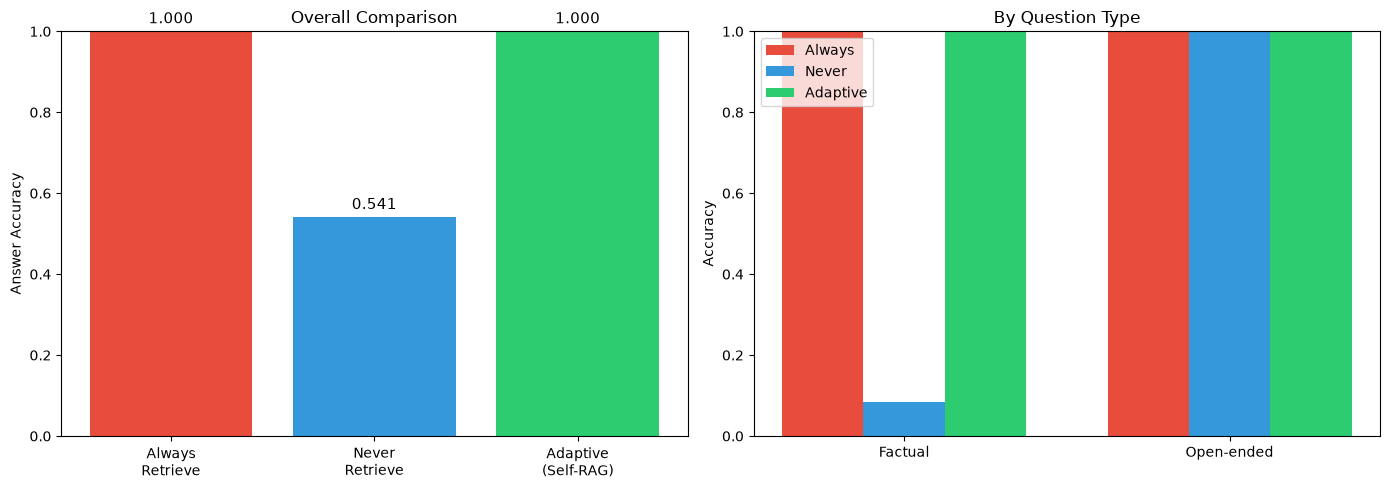

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
modes = ['always', 'never', 'adaptive']
accs = [overall[m] for m in modes]
labels = ['Always\nRetrieve', 'Never\nRetrieve', 'Adaptive\n(Self-RAG)']
colors = ['#e74c3c', '#3498db', '#2ecc71']
bars = axes[0].bar(labels, accs, color=colors)
axes[0].set_ylabel('Answer Accuracy'); axes[0].set_title('Overall Comparison')
axes[0].set_ylim(0, 1.0)
for b, a in zip(bars, accs):
    axes[0].text(b.get_x() + b.get_width() / 2., b.get_height() + 0.02, f'{a:.3f}', ha='center', fontsize=11)
x = np.arange(2); w = 0.25
for i, (m, lab) in enumerate(zip(['always', 'never', 'adaptive'], ['Always', 'Never', 'Adaptive'])):
    vals = [typed['factual'][m], typed['open'][m]]
    axes[1].bar(x + i * w, vals, w, label=lab, color=colors[i])
axes[1].set_xticks(x + w); axes[1].set_xticklabels(['Factual', 'Open-ended'])
axes[1].set_ylabel('Accuracy'); axes[1].set_title('By Question Type')
axes[1].set_ylim(0, 1.0); axes[1].legend()
plt.tight_layout(); plt.show()

## Summary

### What we built
- A tiny 2-layer Transformer decoder with four reflection-token heads (Retrieve, IsRel, IsSup, IsUse) and an answer head
- A dynamic passage provider: factual questions get passages with the correct answer; open-ended questions get passages with distractors
- Two question types with identical format: factual (answer is random, only in passage) and open-ended (answer is in the question, passages contain distractors from the same answer range)
- Multi-task training with passages, combining answer generation and reflection-token prediction
- Three evaluation modes: always-retrieve, never-retrieve, and adaptive (Self-RAG)

### What the run above shows
- **Adaptive retrieval matches always-retrieve:** The adaptive (Self-RAG) mode achieves 100% accuracy, matching always-retrieve and far outperforming never-retrieve (about 54%).
- **Never-retrieve fails on factual:** Without passages, factual accuracy drops to about 8% (answer is random and only in the passage). Open-ended stays at 100% (answer is in the question).
- **Reflection tokens are learned perfectly:** The model predicts Retrieve with 100% accuracy, correctly identifying which subjects need external knowledge.
- **The model retrieves selectively:** It retrieves for 50% of questions, matching the ground truth exactly.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This toy result is not comparable to the paper's headline numbers. The paper uses Llama 2 7B/13B on real benchmarks (PopQA, TriviaQA, PubHealth, ARC, biography generation, ASQA) with a Contriever-MS MARCO retriever and GPT-4-annotated critic training data. Our notebook uses a 449K-parameter model on a synthetic task with a dynamic passage provider. The qualitative finding — that adaptive retrieval matches the best mode for each question type — is consistent.

### Paper reference
Akari Asai, Zeqiu Wu, Yizhong Wang, Avirup Sil, Hannaneh Hajishirzi (2023). *Self-RAG: Learning to Retrieve, Generate, and Critique through Self-Reflection.* ICLR 2024. arXiv:2310.11511.